# 03 - Scénarios : population 2025 → 2030 → 2035

Base : **1er janvier 2025** (la fenêtre de taux 2020-2025 s'y termine). Pas de 5 ans. Survie et naissances (constantes) : fenêtre 2020-2025 dans tous les cas. Seule la **migration** change (le backtest montre que c'est le facteur dominant) :

| Scénario | Taux de migration |
|---|---|
| bas | fenêtre 2013-2018 |
| haut | fenêtre 2020-2025 |
| tirages, 1 profil par simulation (retenu) | un profil tiré parmi les 8 fenêtres glissantes 2013-2018 … 2020-2025, appliqué à tout l'horizon |
| tirages annuels (comparaison) | un profil tiré chaque année |

In [1]:
import sys
sys.path.append('..')
import pandas as pd
from src.chargement import charger_tout, charger_omphale, PROCESSED_DIR
from src.taux import taux_survie_migration
from src.projection import (population_base, projeter, projeter_pas, total_jeunes, interpoler, taux_fenetres,
                            monte_carlo, decomposition_jeunes, decomposition_observee, TRANCHES_JEUNES)
from src.graphiques import graphique_scenarios, graphique_contributions

tables = charger_tout()
pop, deces = tables['pop_aq'], tables['deces_age']
naissances = tables['dep3'].query("indicateur == 'naissances'").set_index('annee')['effectif']

In [2]:
recent = taux_survie_migration(pop, deces, naissances, debut=2020)
fenetres = taux_fenetres(pop, deces, naissances, range(2013, 2021))

def avec_migration_de(debut):
    m = fenetres.query('debut == @debut').set_index(['sexe', 'tranche_arrivee'])['taux_migration_5ans']
    return recent.assign(taux_migration_5ans=recent.set_index(['sexe', 'tranche_arrivee']).index.map(m))

taux_scen = {'Bas : migration 2013-2018': avec_migration_de(2013),
             'Haut : migration 2020-2025': recent}
base = population_base(pop, 2025)
scen = {k: projeter(base, tx, 2025) for k, tx in taux_scen.items()}
pd.DataFrame({k: total_jeunes(v) for k, v in scen.items()}).style.format('{:,.0f}')

,Bas : migration 2013-2018,Haut : migration 2020-2025
annee,,
2025,"115,555","115,555"
2030,"110,743","115,182"
2035,"105,049","110,233"


In [3]:
# solde migratoire de chaque fenêtre : total, et arrivées dans les tranches 15-29 ans
fenetres.assign(jeunes=fenetres.tranche_arrivee.isin(TRANCHES_JEUNES)).groupby('periode').apply(
    lambda d: pd.Series({'solde total': d.migration_nette_5ans.sum(),
                         'solde 15-29 ans': d.loc[d.jeunes, 'migration_nette_5ans'].sum()}),
    include_groups=False).round()

,solde total,solde 15-29 ans
periode,,
2013-2018,21156.0,-13205.0
2014-2019,23930.0,-10357.0
2015-2020,26674.0,-10550.0
2016-2021,29647.0,-10296.0
2017-2022,34954.0,-9270.0
2018-2023,39404.0,-8210.0
2019-2024,41130.0,-10996.0
2020-2025,42587.0,-9877.0


## Tirages aléatoires (incertitude)

**Retenu : un profil de migration par simulation**, appliqué à tout l'horizon. Les régimes de migration durent : le backtest montre deux niveaux distincts en 2013-2018 puis 2018-2023. Avec 8 fenêtres, il n'y a que 8 trajectoires possibles ; les quantiles se lisent comme « la fourchette des régimes observés depuis 2013 ».

**Comparaison : un profil tiré chaque année.** Sur 10 ans, on fait la moyenne de 10 tirages indépendants, si bien que les années hautes et basses se compensent. Un régime durablement bas (comme 2013-2018) devient presque impossible, et l'intervalle **sous-estime l'incertitude**.

In [4]:
def quantiles(mc):
    j = total_jeunes(mc, par=['sim', 'annee']).unstack('annee')
    q = j.quantile([0.05, 0.5, 0.95]).T
    q.columns = ['q05', 'q50', 'q95']
    return q

q_sim = quantiles(monte_carlo(base, recent, fenetres, 2025, n_sim=1000, graine=42, mode='simulation'))
q_an = quantiles(monte_carlo(base, recent, fenetres, 2025, n_sim=1000, graine=42, mode='annuel'))
pd.concat({'1 profil par simulation': q_sim, 'tirage annuel': q_an}, axis=1).style.format('{:,.0f}')

## Décomposition : d'où vient la variation des 15-29 ans ?

Sur un pas de 5 ans, exactement : **ΔJ = cohorte entrante (10-14 ans au départ) − cohorte sortante (25-29 ans au départ) + décès + migration nette**. Périodes observées (migration = résidu) et projetées.

In [5]:
dec = {}
for d in (2015, 2020):
    tx = taux_survie_migration(pop, deces, naissances, debut=d)
    dec[f'{d}-{d + 5}'] = decomposition_jeunes(population_base(pop, d), tx)
for nom, tx in taux_scen.items():
    court = nom.split(' :')[0].lower()
    p2030 = projeter_pas(base, tx)
    dec[f'2025-2030 {court}'] = decomposition_jeunes(base, tx)
    dec[f'2030-2035 {court}'] = decomposition_jeunes(p2030, tx)
dec = pd.DataFrame(dec).T
# contrôle : la décomposition observée retrouve la variation observée
J = lambda a: total_jeunes(pop[(pop.sexe == 'Ensemble') & (pop.annee == a)]).iloc[0]
assert abs(dec.loc['2020-2025', 'variation totale'] - (J(2025) - J(2020))) < 1
dec.round().style.format('{:+,.0f}')

,cohorte entrante (10-14 → 15-19),cohorte sortante (25-29 → 30-34),décès,migration nette,variation totale
2015-2020,"+46,821","-35,506",-207,"-10,550",+558
2020-2025,"+46,642","-32,054",-198,"-9,877","+4,513"
2025-2030 bas,"+45,120","-35,756",-199,"-13,977","-4,812"
2030-2035 bas,"+41,159","-33,416",-192,"-13,245","-5,693"
2025-2030 haut,"+45,120","-35,756",-199,"-9,537",-373
2030-2035 haut,"+41,812","-37,469",-193,"-9,099","-4,949"


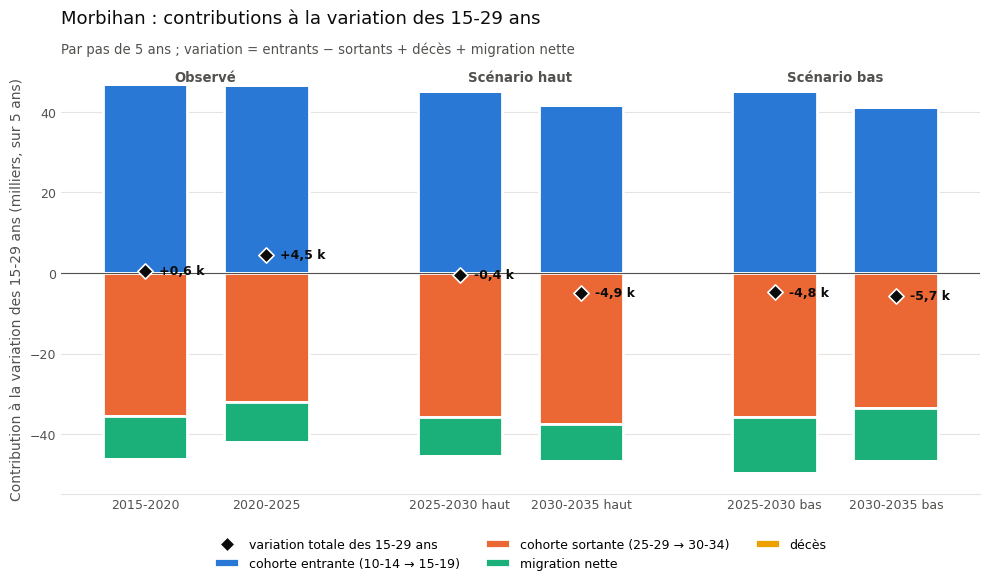

In [6]:
fig, ax = graphique_contributions(
    dec, {'Observé': ['2015-2020', '2020-2025'],
          'Scénario haut': ['2025-2030 haut', '2030-2035 haut'],
          'Scénario bas': ['2025-2030 bas', '2030-2035 bas']},
    'Morbihan : contributions à la variation des 15-29 ans',
    'Par pas de 5 ans ; variation = entrants − sortants + décès + migration nette')
fig.savefig('../figures/contributions_jeunes.png', dpi=150, bbox_inches='tight')

**Lecture** (à confirmer sur les chiffres ci-dessus) : la migration nette des 15-29 ans reste du même ordre (≈ −10 000 par 5 ans en scénario haut, −13 000 à −14 000 en bas). La baisse après 2025 vient du **renouvellement** : la cohorte entrante se réduit (les 10-14 ans passent d'environ 46 600 en 2020 à 41 800 en 2030) tandis que la cohorte sortante grossit (32 000 en 2020, 37 500 en 2030). Ce sont ces arrivées de 25-34 ans entre 2018 et 2025 qui passent ensuite au-delà de 29 ans.

## Comparaison externe : projections Insee Omphale 2022

Omphale (base recensement 2018) projette chaque département avec ses propres hypothèses. Scénarios : central, migrations basses, migrations hautes. Les effectifs Omphale sont arrondis à la dizaine.

In [7]:
omph = pd.concat([charger_omphale(s) for s in ('Central', 'Mig_basse', 'Mig_haute')])
ens = pop[pop.sexe == 'Ensemble']
comp = pd.DataFrame({f'Omphale {s}': total_jeunes(omph[(omph.scenario == s) & omph.annee.isin([2018, 2023, 2025, 2030, 2035])])
                     for s in omph.scenario.unique()})
comp['Observé (estimations)'] = total_jeunes(ens[ens.annee.isin([2018, 2023, 2025])])
for k, v in scen.items():
    comp[k] = total_jeunes(v)
comp.style.format('{:,.0f}', na_rep='')

,Omphale central,Omphale migrations basses,Omphale migrations hautes,Observé (estimations),Bas : migration 2013-2018,Haut : migration 2020-2025
annee,,,,,,
2018,"108,380","108,380","108,380","108,135",,
2023,"110,350","109,930","110,500","113,065",,
2025,"112,730","111,930","113,250","115,555","115,555","115,555"
2030,"116,160","114,630","117,380",,"110,743","115,182"
2035,"112,980","111,140","114,480",,"105,049","110,233"


In [8]:
# 1) backtest d'Omphale : même base (2018) et même cible (2023) que notre backtest
o23, obs23 = comp.loc[2023, 'Omphale central'], comp.loc[2023, 'Observé (estimations)']
from src.projection import backtest, resume_erreurs
e_mod = resume_erreurs(backtest(pop, deces, naissances, debut_calib=2013)).loc['modele', 'erreur 15-29 ans']
print(f"15-29 ans en 2023, projection depuis 2018 : Omphale central {o23 / obs23 - 1:+.1%}, "
      f"notre modèle calibré 2013-2018 {e_mod:+.1%}")
# 2) écart de niveau en 2025 (Omphale part de 2018) et évolutions 2025 -> 2035
evol = (comp.loc[2035] / comp.loc[2025] - 1).dropna()
print(f"Omphale central 2025 vs observé : {comp.loc[2025, 'Omphale central'] / comp.loc[2025, 'Observé (estimations)'] - 1:+.1%}")
evol.rename('évolution 2025 → 2035').to_frame().style.format('{:+.1%}')

15-29 ans en 2023, projection depuis 2018 : Omphale central -2.4%, notre modèle calibré 2013-2018 -4.8%
Omphale central 2025 vs observé : -2.4%


,évolution 2025 → 2035
Omphale central,+0.2%
Omphale migrations basses,-0.7%
Omphale migrations hautes,+1.1%
Bas : migration 2013-2018,-9.1%
Haut : migration 2020-2025,-4.6%


In [9]:
# 3) pourquoi Omphale ne baisse pas : même décomposition appliquée aux populations Omphale
dec_o = {}
for s in omph.scenario.unique():
    o = omph[omph.scenario == s]
    for a in (2025, 2030):
        dec_o[f'Omphale {s} {a}-{a + 5}'] = decomposition_observee(population_base(o, a), population_base(o, a + 5), recent)
pd.concat([pd.DataFrame(dec_o).T, dec.loc[['2025-2030 haut', '2025-2030 bas']]]).round().style.format('{:+,.0f}')

,cohorte entrante (10-14 → 15-19),cohorte sortante (25-29 → 30-34),décès,migration nette,variation totale
Omphale central 2025-2030,"+45,470","-30,520",-204,"-11,316","+3,430"
Omphale central 2030-2035,"+41,780","-33,870",-201,"-10,889","-3,180"
Omphale migrations basses 2025-2030,"+45,470","-30,210",-203,"-12,357","+2,700"
Omphale migrations basses 2030-2035,"+41,650","-33,030",-200,"-11,910","-3,490"
Omphale migrations hautes 2025-2030,"+45,520","-30,640",-204,"-10,546","+4,130"
Omphale migrations hautes 2030-2035,"+41,880","-34,470",-203,"-10,107","-2,900"
2025-2030 haut,"+45,120","-35,756",-199,"-9,537",-373
2025-2030 bas,"+45,120","-35,756",-199,"-13,977","-4,812"


**Lecture.**
- **Cohérence des hypothèses de migration.** La migration nette implicite des 15-29 ans dans Omphale (≈ −10 000 à −12 000 par 5 ans) est comprise entre nos scénarios haut (≈ −9 500) et bas (≈ −14 000).
- **D'où vient la divergence ?** Elle vient de la **structure de départ**. Omphale, construit sur la base 2018, compte environ 30 500 personnes de 25-29 ans en 2025, contre environ 35 800 dans les estimations actuelles : il n'a pas anticipé les arrivées de jeunes adultes de 2018-2025. Sa cohorte sortante est donc plus petite, ce qui explique pourquoi ses 15-29 ans augmentent jusqu'en 2030.
- **Le même biais que nous.** Omphale sous-estime aussi la population 2023 : la migration récente a été plus forte que prévu, par Omphale comme par notre calibrage 2013-2018.

## Comparaison avec la population provisoire 2026

Projection interpolée (géométriquement) entre 2025 et 2030, comparée à l'estimation provisoire Insee du 1er janvier 2026.

In [10]:
def p_annee(df, a):
    return df[df.annee == a].set_index(['sexe', 'tranche_age'])['effectif']

c26 = pd.DataFrame({'Provisoire Insee 2026': population_base(pop, 2026)})
for nom, df in scen.items():
    c26[nom] = interpoler(p_annee(df, 2025), p_annee(df, 2030), 2025, 2030, 2026)
cj = c26[c26.index.get_level_values('tranche_age').isin(TRANCHES_JEUNES)].sum()
pd.DataFrame({'15-29 ans en 2026': cj, 'écart au provisoire': cj / cj.iloc[0] - 1}).style.format(
    {'15-29 ans en 2026': '{:,.0f}', 'écart au provisoire': '{:+.2%}'})

,15-29 ans en 2026,écart au provisoire
Provisoire Insee 2026,"116,385",+0.00%
Bas : migration 2013-2018,"114,568",-1.56%
Haut : migration 2020-2025,"115,469",-0.79%


## Graphique de synthèse

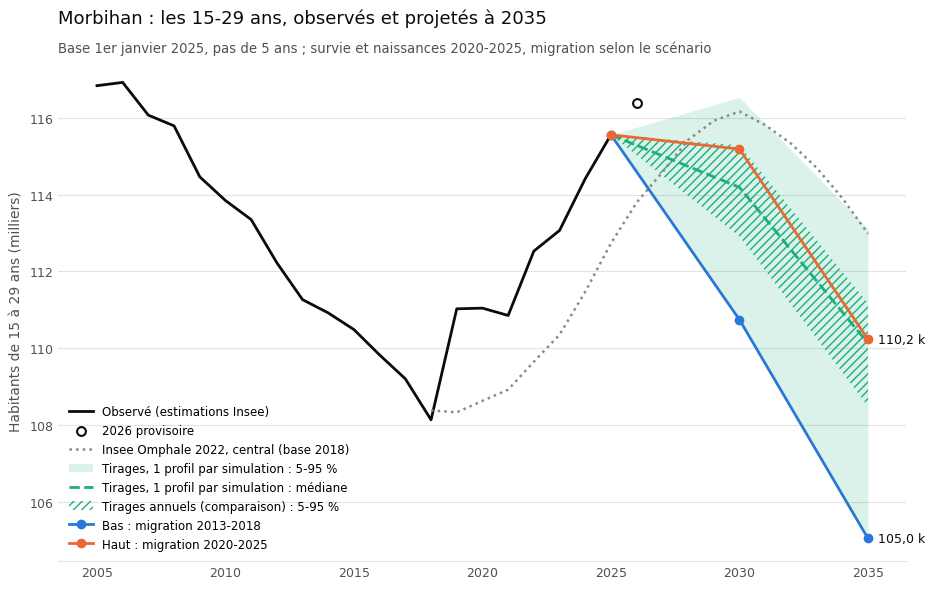

In [11]:
hist = total_jeunes(ens[ens.annee.between(2005, 2025)])
prov_j = total_jeunes(ens[ens.annee == 2026])
omph_c = total_jeunes(omph[(omph.scenario == 'central') & omph.annee.between(2018, 2035)])
fig, ax = graphique_scenarios(
    hist, {k: total_jeunes(v) for k, v in scen.items()}, q_sim,
    'Morbihan : les 15-29 ans, observés et projetés à 2035',
    'Base 1er janvier 2025, pas de 5 ans ; survie et naissances 2020-2025, migration selon le scénario',
    prov=prov_j, mc_annuel=q_an, externe={'Insee Omphale 2022, central (base 2018)': omph_c})
fig.savefig('../figures/scenarios_jeunes_2035.png', dpi=150, bbox_inches='tight')

In [12]:
out = pd.concat([df.assign(scenario=k) for k, df in scen.items()])
out.to_csv(PROCESSED_DIR / 'projections_2025_2035.csv', index=False)
pd.concat({'simulation': q_sim, 'annuel': q_an}).to_csv(PROCESSED_DIR / 'tirages_jeunes_quantiles.csv')
dec.to_csv(PROCESSED_DIR / 'decomposition_jeunes.csv')

## Limites

- **Migration récente sous-estimée.** La population provisoire 2026 est au-dessus des deux scénarios (−0,8 % à −1,6 % sur les 15-29 ans). C'est le même sens que le backtest (−4,8 %) et qu'Omphale : la migration récente est plus forte que celle de nos scénarios, et le scénario haut n'est pas un plafond. **2026 reste provisoire** : l'écart peut changer à la révision des estimations.
- **Peu de fenêtres de calibrage.** 8 fenêtres glissantes qui se chevauchent : la fourchette des tirages décrit les régimes observés depuis 2013, pas une distribution de probabilité.
- **Naissances constantes.** Sans effet sur les 15-29 ans d'ici 2035 (déjà nés) ; elles biaisent seulement les 0-9 ans.
- **Données provisoires** pour 2024-2026 ; décès Eurostat jusqu'à 2024 seulement.